# 05 - Benchmarking and analysis of results

**Aim:** train the final von Heijne and SVM predictors, evaluate them on the independent benchmarking set and interpret their prediction errors.

We reused the prepared proteins and training folds from 02b, the von Heijne functions from 03 and the main 31-feature SVM procedure from 04. Both final predictors were fitted using training data only. We evaluated both fixed predictors on the same 2,038 benchmarking proteins in section 3. Error analysis in sections 4–6 remains to implement.

**Materials**
- `05 - Benchmarking and analysis of results.pdf` (slides 2–3: final models; 4–7: error analysis; 8: summary).
- [03 - Von Heijne method](03_von_heijne_method.ipynb) (sections 1–4: matrix, scoring and threshold; 5: metrics).
- [04 - SVM method](04_svm_method.ipynb) (sections 1–3: features and fitting; 4–5: fold-specific selection; 6: reporting).
- [02c - Data analysis](02c_data_analysis.ipynb) (composition, taxonomy and cleavage-site logos) and [04 feature exploration](04_feature_exploration.ipynb) (feature distributions).

**Status:** sections 0–3 have saved execution and have been internally reviewed. Final-model exports, benchmarking predictions, metrics and two PDF figures are available. Error analysis and interpretation in sections 4–6 remain pending. Internal review is not professor approval.

## Scope and notation

We used the main SVM with 31 candidate features and the fixed 27-combination grid from 04. Experimental SVM variants remain separate. Earlier CV results describe the prediction procedures; the final predictors fitted here are intended for the later benchmarking evaluation (slides 2–3).

Saved folds remain 1–5, corresponding to 0–4 in slide 2. For von Heijne, folds 1–4 fitted the threshold-selection matrix and fold 5 selected the threshold. For SVM, each of the five folds served once as validation.

We retain `n` for composition-region length and `k` for selected-feature count. The regional K in slides 6–7 corresponds to our n. Benchmarking labels, metadata and error patterns must not guide feature design, parameter selection or threshold adjustment.

## 0. Imports and data loading

### 0.1 Imports and paths

We used Conda `LB2` and paths relative to `notebooks/`, following 03–04. Inputs come from `../data/prepared/`; this section writes tables under `../results/tables/05/` and reserves `../results/figures/05/` for its figures. The feature caches from 04 are read-only inputs. WebLogo/Ghostscript setup remains pending with the logo step in section 5.

In [1]:
# Imports follow 04 section 0.1; precision_recall_curve follows the threshold
# selection on slide 23 of 03-Methods-vonHeijne (03 section 4).
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Text progress bars work without Jupyter widgets.
from tqdm import tqdm

from Bio.SeqUtils.ProtParamData import kd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    precision_recall_curve,
    matthews_corrcoef,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

# Paths are relative to notebooks/, as in 03-04. New outputs belong to 05.
input_dir = Path("../data/prepared")
table_dir = Path("../results/tables/05")
figure_dir = Path("../results/figures/05")
# 04 outputs are read-only inputs here (feature caches in 2.1).
svm_04_table_dir = Path("../results/tables/04")

table_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme()

### 0.2 Load sequences, labels and metadata

We reused the accession-based FASTA/TSV loading from 04 section 0.2, preserving the original metadata, split and fold assignments. Labels are 1 for SP and 0 for NO_SP; the negative TM flag is stored as a nullable boolean.

The loaded tables contain 8,146 training proteins (881 SP, 7,265 NO_SP) and 2,038 benchmarking proteins (221 SP, 1,817 NO_SP). `data` contains training only; `benchmarking_data` remains separate from all fitting and selection in sections 1–2 (slide 2).

In [2]:
# The reader and accession-based loading are reused from 04 section 0.2.
def read_fasta(fasta_path):
    sequences = {}
    with open(fasta_path, encoding="utf-8") as fasta_in:
        for line in fasta_in:
            line = line.strip()
            if line.startswith(">"):
                accession = line[1:].split()[0]
                sequences[accession] = ""
            elif line:
                sequences[accession] += line
    return sequences


positive_data = pd.read_csv(
    input_dir / "positive_dataset.tsv", sep="\t", dtype={"cv_fold": "Int64"}
)
negative_data = pd.read_csv(
    input_dir / "negative_dataset.tsv", sep="\t", dtype={"cv_fold": "Int64"}
)
positive_sequences = read_fasta(input_dir / "positive_dataset.fasta")
negative_sequences = read_fasta(input_dir / "negative_dataset.fasta")

positive_data["sequence"] = positive_data["accession"].map(positive_sequences)
negative_data["sequence"] = negative_data["accession"].map(negative_sequences)
positive_data["label"] = 1
negative_data["label"] = 0


# Parse the TM flag as a boolean before combining the tables;
# an unexpected value stops the cell instead of being guessed.
def parse_tm_flag(value):
    if pd.isna(value):
        return pd.NA
    text = str(value).strip().lower()
    if text in {"true", "1", "1.0", "yes"}:
        return True
    if text in {"false", "0", "0.0", "no"}:
        return False
    raise ValueError(f"Unexpected has_tm_in_90 value: {value!r}")


for table in [positive_data, negative_data]:
    if "has_tm_in_90" in table.columns:
        table["has_tm_in_90"] = table["has_tm_in_90"].map(parse_tm_flag).astype("boolean")

# Keep the saved partitions and folds 1-5 from 02b (slide 2).
prepared_data = pd.concat([positive_data, negative_data], ignore_index=True)
# Positives have no TM flag, so they keep a missing value.
prepared_data["has_tm_in_90"] = prepared_data["has_tm_in_90"].astype("boolean")

data = prepared_data[prepared_data["split"] == "training"].copy()
benchmarking_data = prepared_data[prepared_data["split"] == "benchmarking"].copy()

print("Training proteins:", len(data))
print("Benchmarking proteins:", len(benchmarking_data))
display(
    prepared_data.groupby(["split", "label"]).size().unstack("label")
    .rename(columns={0: "NO_SP", 1: "SP"})
)
display(
    data.groupby(["cv_fold", "label"]).size().unstack("label")
    .rename(columns={0: "NO_SP", 1: "SP"})
)

# Checks against the counts expected from 02b.
expected_counts = {
    ("training", 1): 881, ("training", 0): 7265,
    ("benchmarking", 1): 221, ("benchmarking", 0): 1817,
}
for (split, label), expected in expected_counts.items():
    observed = int(((prepared_data["split"] == split) & (prepared_data["label"] == label)).sum())
    assert observed == expected, f"{split}, label {label}: {observed} instead of {expected}"
assert prepared_data["sequence"].notna().all(), "Some accessions have no sequence"
assert sorted(data["cv_fold"].unique().tolist()) == [1, 2, 3, 4, 5]
print("Loading checks passed")

Training proteins: 8146
Benchmarking proteins: 2038


label,NO_SP,SP
split,,
benchmarking,1817,221
training,7265,881


label,NO_SP,SP
cv_fold,,
1,1453,177
2,1453,176
3,1453,176
4,1453,176
5,1453,176


Loading checks passed


## 1. Final von Heijne predictor

### 1.1 Estimate the threshold-selection matrix

We reused the context, matrix and scoring functions from 03 sections 1–3: 15-position contexts (−13…−1,+1,+2), pseudocount 1, the fixed SwissProt background and maximum complete-window score within the first 90 residues. Unknown residues contribute zero during scoring without shifting positions.

Positive proteins in folds 1–4 supplied 705 contexts, with none excluded. Their matrix scored both classes in validation fold 5 (1,629 proteins, including 176 SP). Validation proteins did not contribute to matrix estimation (slides 2–3).

In [3]:
# extract_cleavage_contexts and build_pswm are reused from 03 sections 1.3 and 2
# unchanged; score_sequence and score_dataset below come from 03 section 3.
def extract_cleavage_contexts(train):
    contexts = []
    excluded = []
    positives = train[train["label"] == 1]
    for row in positives.itertuples(index=False):
        c = int(row.cleavage_pos)
        # A full -13...+2 context is needed; otherwise the protein is excluded.
        if c < 13 or c + 2 > len(row.sequence):
            excluded.append(row.accession)
            continue
        contexts.append({
            "accession": row.accession,
            "cv_fold": row.cv_fold,
            "context": row.sequence[c - 13:c + 2],
        })
    return pd.DataFrame(contexts, columns=["accession", "cv_fold", "context"]), excluded


def build_pswm(contexts_df, background_freqs=None):
    aa_alphabet = sorted("ACDEFGHIKLMNPQRSTVWY")
    n_positions = 15  
    
    if background_freqs is None:
        background_freqs = {
            "A": 8.25, "C": 1.38, "D": 5.46, "E": 6.71, "F": 3.86,
            "G": 7.07, "H": 2.27, "I": 5.90, "K": 5.79, "L": 9.64,
            "M": 2.41, "N": 4.06, "P": 4.75, "Q": 3.93, "R": 5.52,
            "S": 6.66, "T": 5.36, "V": 6.85, "W": 1.10, "Y": 2.92,
        }
        
    counts = np.ones((len(aa_alphabet), n_positions))
    aa_to_index = {aa: idx for idx, aa in enumerate(aa_alphabet)}
    
    for context_str in contexts_df["context"]:
        for pos_idx, aa in enumerate(context_str):
            if aa in aa_to_index:
                counts[aa_to_index[aa], pos_idx] += 1
                
    pspm = counts / counts.sum(axis=0)
    bg_vector = np.array([background_freqs[aa] for aa in aa_alphabet]).reshape(-1, 1)
    
    bg_vector = bg_vector / bg_vector.sum()

    pswm_array = np.log(pspm / bg_vector)

    position_labels = [f"P{i}" for i in range(-13, 3) if i != 0]
    pswm_df = pd.DataFrame(pswm_array, index=aa_alphabet, columns=position_labels)
    
    return pswm_df


# score_sequence and score_dataset are reused from 03 section 3:
# complete windows within the first 90 residues; unknown residues contribute 0.
n_terminal_length = 90


def score_sequence(sequence, pswm_df):
    weights = pswm_df.to_numpy()
    aa_index = {aa: i for i, aa in enumerate(pswm_df.index)}
    window_length = weights.shape[1]

    n_terminus = sequence[:n_terminal_length]
    best_score, best_start = -np.inf, None

    for start in range(len(n_terminus) - window_length + 1):
        window = n_terminus[start:start + window_length]
        score = 0.0
        for position, aa in enumerate(window):
            if aa in aa_index:
                score += weights[aa_index[aa], position]
        if score > best_score:
            best_score, best_start = score, start + 1

    return best_score, best_start


def score_dataset(proteins, pswm_df):
    scored = proteins.copy()
    results = [score_sequence(sequence, pswm_df) for sequence in scored["sequence"]]
    scored["score"] = [score for score, _ in results]
    scored["best_start"] = [start for _, start in results]
    return scored


# Threshold-selection scheme (slide 2): matrix from folds 1-4, threshold on fold 5.
vh_matrix_folds = [1, 2, 3, 4]
vh_validation_fold = 5
vh_train = data[data["cv_fold"].isin(vh_matrix_folds)].copy()
vh_validation = data[data["cv_fold"] == vh_validation_fold].copy()

selection_contexts, selection_excluded = extract_cleavage_contexts(vh_train)
selection_pswm = build_pswm(selection_contexts)
vh_validation_scored = score_dataset(vh_validation, selection_pswm)

print("Matrix training proteins (folds 1-4):", len(vh_train))
print("Training contexts:", len(selection_contexts),
      "| excluded positives:", len(selection_excluded))
print("Validation proteins (fold 5):", len(vh_validation_scored),
      "| SP:", int(vh_validation_scored["label"].sum()))
display(
    vh_validation_scored.groupby("label")["score"].describe().round(2)
    .rename(index={0: "NO_SP", 1: "SP"})
)

# Checks: 15-residue contexts, no validation protein in the matrix.
assert selection_contexts["context"].str.len().eq(15).all()
assert set(selection_contexts["accession"]).isdisjoint(vh_validation["accession"])
print("Matrix checks passed")

Matrix training proteins (folds 1-4): 6517
Training contexts: 705 | excluded positives: 0
Validation proteins (fold 5): 1629 | SP: 176


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
NO_SP,1453.0,0.78,3.10,-11.37,-1.36,0.80,2.97,10.66
SP,176.0,7.80,2.55,-0.36,6.34,7.88,9.32,14.68


Matrix checks passed


### 1.2 Select the final threshold

We reused `find_optimal_threshold` from 03 section 4 to maximize F1 on fold 5, keeping the first maximum in a tie and the decision rule `score >= threshold`. The professor mentioned this four-plus-one validation scheme.

The selected threshold was 6.494453, with validation F1 0.754386. `1_2_von_heijne_threshold.tsv` records the cutoff, validation metrics and training/validation provenance. These are selection results, not final benchmarking performance (slide 3).

In [4]:
# find_optimal_threshold is reused unchanged from 03 section 4.5 (slide 23 of
# 03-Methods-vonHeijne): maximum validation F1 on the precision-recall curve,
# first maximum in a tie.
def find_optimal_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        scores
    )

    f1_scores = np.divide(
        2 * precision[:-1] * recall[:-1],
        precision[:-1] + recall[:-1],
        out=np.zeros_like(precision[:-1]),
        where=(precision[:-1] + recall[:-1]) != 0
    )

    best_index = np.argmax(f1_scores)

    best_threshold = thresholds[best_index]
    best_f1 = f1_scores[best_index]

    return best_threshold, best_f1


vh_threshold, vh_validation_f1 = find_optimal_threshold(
    vh_validation_scored["label"].to_numpy(),
    vh_validation_scored["score"].to_numpy(),
)
vh_threshold = float(vh_threshold)

# Classify fold 5 with the 03 decision rule (score >= threshold).
y_vh_validation = vh_validation_scored["label"].to_numpy()
vh_validation_predictions = (vh_validation_scored["score"] >= vh_threshold).astype(int)

# Check: recomputing F1 from these predictions gives the F1 returned above.
check_f1 = f1_score(y_vh_validation, vh_validation_predictions)
assert np.isclose(check_f1, vh_validation_f1), "Threshold and F1 do not match"

# Selection record with provenance; validation F1 is a selection score, not performance.
threshold_record = pd.DataFrame([{
    "threshold": vh_threshold,
    "decision_rule": "score >= threshold",
    "selection_rule": "maximum validation F1 on the precision-recall curve; first maximum in a tie",
    "log_base": "natural",
    "matrix_training_folds": ",".join(map(str, vh_matrix_folds)),
    "validation_fold": vh_validation_fold,
    "training_contexts": len(selection_contexts),
    "excluded_training_positives": len(selection_excluded),
    "validation_proteins": len(vh_validation_scored),
    "validation_sp": int(vh_validation_scored["label"].sum()),
    "validation_precision": precision_score(y_vh_validation, vh_validation_predictions),
    "validation_recall": recall_score(y_vh_validation, vh_validation_predictions),
    "validation_f1": float(vh_validation_f1),
}])

threshold_path = table_dir / "1_2_von_heijne_threshold.tsv"
threshold_record.to_csv(threshold_path, sep="\t", index=False)
print("Threshold record saved in:", threshold_path)
print(f"Selected threshold: {vh_threshold:.4f}")
threshold_record.T

Threshold record saved in: ../results/tables/05/1_2_von_heijne_threshold.tsv
Selected threshold: 6.4945


,0
threshold,6.494453
decision_rule,score >= threshold
selection_rule,maximum validation F1 on the precision-recall ...
log_base,natural
matrix_training_folds,"1,2,3,4"
validation_fold,5
training_contexts,705
excluded_training_positives,0
validation_proteins,1629
validation_sp,176


### 1.3 Retrain the final matrix

We rebuilt the matrix with all 881 training-positive contexts and kept the threshold from 1.2 unchanged (slide 3). No positives were excluded. The final matrix and contexts are saved as `1_3_von_heijne_matrix.tsv` and `1_3_von_heijne_contexts.tsv`.

`final_pswm` and `final_vh_threshold` define the von Heijne predictor for section 3. The matrix is shown below and is applied with the fixed threshold in section 3.

In [5]:
# Final matrix from all five training folds, with the same contexts and scoring (slide 3).
final_contexts, final_excluded = extract_cleavage_contexts(data)
final_pswm = build_pswm(final_contexts)
# The threshold selected in 1.2 is kept unchanged after retraining.
final_vh_threshold = vh_threshold

matrix_path = table_dir / "1_3_von_heijne_matrix.tsv"
contexts_path = table_dir / "1_3_von_heijne_contexts.tsv"
final_pswm.to_csv(matrix_path, sep="\t", index_label="amino_acid")
final_contexts.to_csv(contexts_path, sep="\t", index=False)
print("Final matrix saved in:", matrix_path)
print("Final contexts saved in:", contexts_path)

print("Training SP proteins:", int((data["label"] == 1).sum()))
print("Final contexts:", len(final_contexts), "| excluded positives:", len(final_excluded))
print(f"Fixed threshold (from 1.2): {final_vh_threshold:.4f}")

# Check: every training positive is either used or excluded.
assert len(final_contexts) + len(final_excluded) == int((data["label"] == 1).sum())
print("Final matrix checks passed")

final_pswm.round(2)

Final matrix saved in: ../results/tables/05/1_3_von_heijne_matrix.tsv
Final contexts saved in: ../results/tables/05/1_3_von_heijne_contexts.tsv
Training SP proteins: 881
Final contexts: 881 | excluded positives: 0
Fixed threshold (from 1.2): 6.4945
Final matrix checks passed


,P-13,P-12,P-11,P-10,P-9,P-8,P-7,P-6,P-5,P-4,P-3,P-2,P-1,P1,P2
A,0.26,0.20,0.17,0.18,0.77,0.76,0.39,0.68,0.64,0.19,1.25,0.09,1.82,0.62,-0.55
C,1.01,0.61,0.85,0.88,0.85,1.54,1.29,0.85,0.57,0.66,1.47,-0.04,0.91,0.31,0.37
D,-2.29,-3.90,-3.90,-3.90,-2.51,-2.29,-2.51,-1.59,-0.80,-0.95,-2.80,-0.28,-2.10,0.28,0.03
E,-2.49,-3.41,-3.41,-2.72,-2.31,-2.16,-1.91,-1.90,-0.84,-0.61,-2.16,0.09,-2.31,0.09,0.24
F,0.79,0.78,0.30,0.73,0.51,0.44,0.68,0.38,-0.60,-0.08,-2.45,-0.33,-2.16,-0.02,-0.37
G,-0.90,-0.98,-0.75,-0.52,-0.47,-0.60,-0.47,-0.72,0.56,0.47,0.16,-0.57,1.02,-0.03,-0.33
H,-1.63,-2.33,-1.63,-2.33,-1.07,-1.41,-0.72,-0.53,0.20,-0.62,-2.32,0.77,-2.32,0.16,0.31
I,0.09,0.26,0.30,0.09,-0.34,-0.39,-0.19,0.34,-1.03,-0.88,-0.42,-0.98,-3.28,-0.54,-0.54
K,-2.35,-2.86,-3.95,-3.26,-3.96,-3.26,-2.01,-2.86,-1.32,-1.25,-2.01,-0.82,-1.88,-0.27,-0.06
L,1.37,1.53,1.39,1.49,1.30,1.09,1.25,0.72,-0.39,0.44,-1.00,0.33,-1.98,0.01,-0.75


## 2. Final SVM predictor

### 2.1 Reuse feature extraction and define the search

We reused the 31 sequence-feature definitions and fitting helpers from 04 sections 1–3. Each fitting subset determines `n = ceil(median positive cleavage_pos)`. RF ranking uses 500 trees and seed 0; StandardScaler and the RBF SVC are fitted on the corresponding training proteins.

The cache stores sequence-only descriptors indexed by accession. Compatible tables from 04 can be reused; newly computed tables belong to 05. Benchmark proteins use `extract_features(proteins, n)` rather than this training cache.

The ordered grid contains 27 candidates: k = 8, 16, 31; C = 1, 4, 16; gamma = factor/k with factors 0.5, 1, 2. These are the agreed settings retained from 04, while 05 slide 3 specifies the final five-fold selection procedure.

In [6]:
# Composition length n: training-only median SP length, from 04 section 1.1 (SVM slides 30, 40).
def get_n(train_data):
    sp_lengths = train_data.loc[train_data["label"] == 1, "cleavage_pos"]
    median_length = sp_lengths.median()
    # Rounding upward is our project convention.
    return int(np.ceil(median_length))


# Fixed feature settings and residue policy, from 04 section 1.2.
hydropathy_scale = kd
aa_alphabet = list("ACDEFGHIKLMNPQRSTVWY")

hydropathy_length = 40
hydropathy_window = 5
charge_length = 5
hydropathy_threshold = 0.0
postpeak_length = 5
postpeak_small_residues = "AGS"
cleavage_small_residues = "ACGST"
propensity_length = 40
alpha_helix_window = 5
tm_tendency_window = 19

# Chou-Fasman alpha-helix propensity (ProtScale).
alpha_helix_scale = {
    "A": 1.42, "C": 0.70, "D": 1.01, "E": 1.51, "F": 1.13,
    "G": 0.57, "H": 1.00, "I": 1.08, "K": 1.16, "L": 1.21,
    "M": 1.45, "N": 0.67, "P": 0.57, "Q": 1.11, "R": 0.98,
    "S": 0.77, "T": 0.83, "V": 1.06, "W": 1.08, "Y": 0.69,
}
# Zhao-London transmembrane tendency (ProtScale).
tm_tendency_scale = {
    "A": 0.38, "C": -0.30, "D": -3.27, "E": -2.90, "F": 1.98,
    "G": -0.19, "H": -1.44, "I": 1.97, "K": -3.46, "L": 1.82,
    "M": 1.40, "N": -1.62, "P": -1.44, "Q": -1.84, "R": -2.57,
    "S": -0.53, "T": -0.32, "V": 1.46, "W": 1.53, "Y": 0.49,
}


# 2.1 in 04: composition of canonical residues in the first n positions.
composition_feature_names = [f"aa_fraction_{amino_acid}" for amino_acid in aa_alphabet]


def amino_acid_composition(sequence, n):
    counts = dict.fromkeys(aa_alphabet, 0)
    observed = 0
    for residue in sequence[:n]:
        if residue in counts:
            counts[residue] += 1
            observed += 1
    if observed == 0:
        return {name: np.nan for name in composition_feature_names}
    return {
        f"aa_fraction_{amino_acid}": counts[amino_acid] / observed
        for amino_acid in aa_alphabet
    }


# 2.2 in 04: complete-window scale profiles and KD summaries.
hydropathy_feature_names = [
    f"hydropathy_max_w{hydropathy_window}",
    f"hydropathy_profile_mean_w{hydropathy_window}",
]


def scale_profile(sequence, scale, window, length):
    values = [scale.get(residue, np.nan) for residue in sequence[:length]]
    profile = []
    for start in range(len(values) - window + 1):
        window_values = [
            value for value in values[start : start + window] if not np.isnan(value)
        ]
        profile.append(float(np.mean(window_values)) if window_values else np.nan)
    return profile


def hydropathy_profile(sequence):
    return scale_profile(sequence, hydropathy_scale, hydropathy_window, hydropathy_length)


def hydropathy_features(sequence):
    profile = [value for value in hydropathy_profile(sequence) if not np.isnan(value)]
    if not profile:
        return {name: np.nan for name in hydropathy_feature_names}
    return dict(zip(hydropathy_feature_names, [max(profile), float(np.mean(profile))]))


# 2.3 in 04: N-terminal charge proxy.
charge_feature_names = [f"nterminal_charge_first{charge_length}"]


def nterminal_charge(sequence):
    residues = [residue for residue in sequence[:charge_length] if residue in aa_alphabet]
    if not residues:
        return np.nan
    positive = sum(residue in "KR" for residue in residues)
    negative = sum(residue in "DE" for residue in residues)
    return (positive - negative) / len(residues)


def charge_features(sequence):
    return {charge_feature_names[0]: nterminal_charge(sequence)}


# 2.4 in 04: alpha-helix propensity summaries.
alpha_helix_feature_names = [
    f"alpha_helix_profile_mean_w{alpha_helix_window}",
    f"alpha_helix_max_w{alpha_helix_window}",
]


def alpha_helix_profile(sequence):
    return scale_profile(sequence, alpha_helix_scale, alpha_helix_window, propensity_length)


def alpha_helix_features(sequence):
    profile = [value for value in alpha_helix_profile(sequence) if not np.isnan(value)]
    if not profile:
        return {name: np.nan for name in alpha_helix_feature_names}
    return dict(zip(alpha_helix_feature_names, [float(np.mean(profile)), max(profile)]))


# 2.5 in 04: transmembrane tendency summaries.
tm_tendency_feature_names = [
    f"tm_tendency_profile_mean_w{tm_tendency_window}",
    f"tm_tendency_max_w{tm_tendency_window}",
]


def tm_tendency_profile(sequence):
    return scale_profile(sequence, tm_tendency_scale, tm_tendency_window, propensity_length)


def tm_tendency_features(sequence):
    profile = [value for value in tm_tendency_profile(sequence) if not np.isnan(value)]
    if not profile:
        return {name: np.nan for name in tm_tendency_feature_names}
    return dict(zip(tm_tendency_feature_names, [float(np.mean(profile)), max(profile)]))


# 2.6 in 04: four additional sequence descriptors.
additional_feature_names = [
    "hydropathy_peak_position",
    "hydrophobic_stretch_length",
    "postpeak_small_fraction",
    "cleavage_motif_score",
]


def hydropathy_peak_position(sequence):
    profile = hydropathy_profile(sequence)
    if not profile or np.all(np.isnan(profile)):
        return np.nan
    peak_start = int(np.nanargmax(profile))
    return peak_start + hydropathy_window // 2 + 1


def hydrophobic_stretch_length(sequence):
    profile = hydropathy_profile(sequence)
    if not profile or np.all(np.isnan(profile)):
        return np.nan
    current_run = 0
    longest_run = 0
    for value in profile:
        if value > hydropathy_threshold:
            current_run += 1
            longest_run = max(longest_run, current_run)
        else:
            current_run = 0
    return longest_run + hydropathy_window - 1 if longest_run else 0


def postpeak_small_fraction(sequence):
    peak = hydropathy_peak_position(sequence)
    if np.isnan(peak):
        return np.nan
    window_end = int(peak) + hydropathy_window // 2
    region = sequence[window_end : min(window_end + postpeak_length, hydropathy_length)]
    if not region:
        return 0.0
    residues = [residue for residue in region if residue in aa_alphabet]
    if not residues:
        return np.nan
    return sum(residue in postpeak_small_residues for residue in residues) / len(residues)


def cleavage_motif_score(sequence):
    peak = hydropathy_peak_position(sequence)
    if np.isnan(peak):
        return np.nan
    first_site = max(int(peak) + hydropathy_window // 2, 3)
    last_site = min(hydropathy_length, len(sequence) - 1)
    scores = []
    for site in range(first_site, last_site + 1):
        residues = [sequence[site - 3], sequence[site - 1]]
        if all(residue in aa_alphabet for residue in residues):
            scores.append(sum(residue in cleavage_small_residues for residue in residues) / 2)
    return max(scores) if scores else 0.0


def additional_features(sequence):
    return {
        additional_feature_names[0]: hydropathy_peak_position(sequence),
        additional_feature_names[1]: hydrophobic_stretch_length(sequence),
        additional_feature_names[2]: postpeak_small_fraction(sequence),
        additional_feature_names[3]: cleavage_motif_score(sequence),
    }


# Check against the worked example on SVM slide 30 (as in 04 section 2.1).
slide_example = amino_acid_composition("MRFLAATFLLLALSTAAQAEPQF", 21)
assert round(slide_example["aa_fraction_A"], 2) == 0.29
assert round(slide_example["aa_fraction_L"], 2) == 0.24
assert np.isclose(sum(slide_example.values()), 1)
print("Feature functions defined; slide 30 composition check passed")

Feature functions defined; slide 30 composition check passed


In [7]:
# Feature order and extractor from 04 section 2.7 (D = 31 for the k grid).
feature_names = (
    composition_feature_names + hydropathy_feature_names + charge_feature_names
    + alpha_helix_feature_names + tm_tendency_feature_names + additional_feature_names
)
D = len(feature_names)


# show_progress is our addition, so small checks can run without a progress bar.
def extract_features(proteins, n, show_progress=True):
    records = []
    for sequence in tqdm(
        proteins["sequence"], desc="Extracting features", unit="protein",
        disable=not show_progress,
    ):
        record = {}
        record.update(amino_acid_composition(sequence, n))
        record.update(hydropathy_features(sequence))
        record.update(charge_features(sequence))
        record.update(alpha_helix_features(sequence))
        record.update(tm_tendency_features(sequence))
        record.update(additional_features(sequence))
        records.append(record)
    features = pd.DataFrame(records, index=pd.Index(proteins["accession"], name="accession"))
    return features[feature_names]


# Training-only feature tables, adapted from get_cached_features in 04 section 2.8.
# Tables are searched in 05 first, then in 04; a table is used only if compatible.
# New tables are saved in 05. Benchmarking features are never taken from this cache.
feature_cache_dir = table_dir / "feature_cache"
feature_cache_dir.mkdir(parents=True, exist_ok=True)
cache_search_dirs = [feature_cache_dir, svm_04_table_dir / "feature_cache"]
fixed_feature_names = feature_names[len(composition_feature_names):]
training_accessions = set(data["accession"])
training_feature_tables = {}


def is_compatible_table(table, n):
    """Same 31 columns, the same training proteins and identical values on a sample."""
    if list(table.columns) != feature_names:
        return False
    if set(table.index) != training_accessions:
        return False
    sample = data.iloc[::400]  # about 20 proteins spread over both classes
    recomputed = extract_features(sample, n, show_progress=False)
    cached = table.loc[sample["accession"], feature_names]
    return np.allclose(recomputed.to_numpy(), cached.to_numpy(), equal_nan=True)


def load_or_build_training_table(n):
    file_name = f"training_features_n{n}.tsv"
    for cache_dir in cache_search_dirs:
        cache_path = cache_dir / file_name
        if cache_path.exists():
            table = pd.read_csv(
                cache_path, sep="\t", index_col="accession", float_precision="round_trip"
            )
            if is_compatible_table(table, n):
                print("Loaded compatible feature table:", cache_path)
                return table
            print("Skipped incompatible feature table:", cache_path)

    # As in 04: reuse the 11 fixed-region features of a table already in memory
    # and recompute only the 20 composition fractions for this n.
    reference = next(iter(training_feature_tables.values()), None)
    if reference is None:
        table = extract_features(data, n)
    else:
        composition = pd.DataFrame(
            [
                amino_acid_composition(sequence, n)
                for sequence in tqdm(data["sequence"], desc=f"Composition (n={n})", unit="protein")
            ],
            index=pd.Index(data["accession"], name="accession"),
        )
        table = pd.concat([composition, reference[fixed_feature_names]], axis=1)[feature_names]

    cache_path = feature_cache_dir / file_name
    table.to_csv(cache_path, sep="\t")
    print("Saved feature table:", cache_path)
    return table


def get_training_features(proteins, n):
    """Features of training proteins for this n, in the row order of `proteins`."""
    unknown = set(proteins["accession"]) - training_accessions
    if unknown:
        raise ValueError(
            f"{len(unknown)} proteins are not training proteins; "
            "use extract_features(proteins, n) for benchmarking proteins."
        )
    if n not in training_feature_tables:
        training_feature_tables[n] = load_or_build_training_table(n)
    return training_feature_tables[n].loc[proteins["accession"], feature_names].copy()


def aligned_labels(features, proteins):
    """Labels in the row order of a feature table."""
    return features.index.map(proteins.set_index("accession")["label"]).to_numpy()


print("Feature count D:", D)

Feature count D: 31


In [8]:
# RF ranking from 04 section 3.1 (SVM slide 35): 500 trees, seed 0.
def rank_features(X_train, y_train):
    rf = RandomForestClassifier(n_estimators=500, random_state=0)
    rf.fit(X_train, y_train)
    importances = rf.feature_importances_
    ranking = np.argsort(importances)[::-1]
    ranked_features = X_train.columns[ranking].tolist()
    ranked_importances = importances[ranking]
    return ranking, ranked_features, ranked_importances


# Scaling and RBF SVC from 04 section 3.3.
def fit_svm(X_train, y_train, C, gamma):
    scaler = StandardScaler().fit(X_train)
    model = SVC(C=C, kernel="rbf", gamma=gamma)
    model.fit(scaler.transform(X_train), y_train)
    return scaler, model


def predict_svm(X, scaler, model):
    return model.predict(scaler.transform(X))


# Ordered 27-candidate grid from 04 section 3.2 (SVM slide 38): smaller k first.
k_values = sorted({int(np.ceil(D / 4)), int(np.ceil(D / 2)), D})
C_values = [1, 4, 16]
gamma_factors = [0.5, 1, 2]
parameter_grid = [
    (k, C, factor / k) for k in k_values for C in C_values for factor in gamma_factors
]

assert len(parameter_grid) == 27
print("Feature counts:", k_values)
print("C values:", C_values)
print("Gamma factors (gamma = factor / k):", gamma_factors)
print("Candidates:", len(parameter_grid))

Feature counts: [8, 16, 31]
C values: [1, 4, 16]
Gamma factors (gamma = factor / k): [0.5, 1, 2]
Candidates: 27


### 2.2 Select settings by five-fold cross-validation

Each saved fold was validation once; the other four supplied n, RF ranking, selected features, scaler and SVM. We selected `(k, C, gamma)` by mean validation MCC over all five folds, retaining the first grid candidate in an exact tie (slides 2–3; mean MCC was also mentioned by the professor).

The search evaluated 135 fold/candidate combinations and used n = 22 in each fitting subset. It selected k = 31, C = 4 and gamma = 0.5/31, with mean validation MCC 0.857393. `2_2_svm_search.tsv` and `2_2_svm_settings.tsv` retain the scores and selected configuration.

This search selected the final settings rather than estimating independent performance. Its scores remain separate from the earlier CV estimates and the final benchmarking evaluation in section 3.

In [9]:
# Five-fold search: each fold validates once while the other four fit (slides 2-3).
# n, RF ranking, scaler and SVM are fitted on the four fitting folds only.
fold_ids = sorted(data["cv_fold"].unique().tolist())
search_records = []

with tqdm(
    total=len(fold_ids) * len(parameter_grid), desc="SVM fits", unit="fit", mininterval=0.5
) as progress:
    for validation_fold in fold_ids:
        fit_train = data[data["cv_fold"] != validation_fold]
        fit_validation = data[data["cv_fold"] == validation_fold]
        n = get_n(fit_train)

        X_train = get_training_features(fit_train, n)
        X_validation = get_training_features(fit_validation, n)
        y_train = aligned_labels(X_train, fit_train)
        y_validation = aligned_labels(X_validation, fit_validation)

        progress.set_postfix(val=validation_fold, stage="RF")
        _, ranked_features, _ = rank_features(X_train, y_train)

        progress.set_postfix(val=validation_fold, stage="SVM")
        for k, C, gamma in parameter_grid:
            selected_names = ranked_features[:k]
            scaler, model = fit_svm(X_train[selected_names], y_train, C, gamma)
            y_pred = predict_svm(X_validation[selected_names], scaler, model)
            search_records.append({
                "validation_fold": validation_fold,
                "n": n,
                "k": k,
                "C": C,
                "gamma": gamma,
                "gamma_factor": gamma * k,
                "mcc": matthews_corrcoef(y_validation, y_pred),
            })
            progress.update(1)

svm_search = pd.DataFrame(search_records)

# Mean validation MCC per candidate; sort=False keeps the grid order,
# so idxmax keeps the first grid candidate in an exact tie.
mean_search = svm_search.groupby(["k", "C", "gamma"], sort=False, as_index=False).agg(
    mean_mcc=("mcc", "mean"), sd_mcc=("mcc", "std"), folds=("mcc", "size")
)
best_row = mean_search.loc[mean_search["mean_mcc"].idxmax()]
svm_settings = {
    "k": int(best_row["k"]),
    "C": float(best_row["C"]),
    "gamma": float(best_row["gamma"]),
}
svm_settings["gamma_factor"] = svm_settings["gamma"] * svm_settings["k"]

# Checks: 5 folds x 27 candidates, every candidate scored on all five folds.
assert len(svm_search) == len(fold_ids) * len(parameter_grid)
assert (mean_search["folds"] == len(fold_ids)).all()

settings_record = pd.DataFrame([{
    **svm_settings,
    "mean_validation_mcc": best_row["mean_mcc"],
    "sd_validation_mcc": best_row["sd_mcc"],
    "validation_folds": ",".join(map(str, fold_ids)),
    "n_per_fold": ",".join(
        str(svm_search.loc[svm_search["validation_fold"] == fold, "n"].iloc[0])
        for fold in fold_ids
    ),
    "selection_rule": "highest mean validation MCC over five folds; first grid candidate in a tie",
}])

search_path = table_dir / "2_2_svm_search.tsv"
settings_path = table_dir / "2_2_svm_settings.tsv"
svm_search.to_csv(search_path, sep="\t", index=False)
settings_record.to_csv(settings_path, sep="\t", index=False)
print("Search records saved in:", search_path)
print("Selected settings saved in:", settings_path)

print("Selected settings:", svm_settings)
print(f"Mean validation MCC (selection score): {best_row['mean_mcc']:.4f}")
mean_search.sort_values("mean_mcc", ascending=False).head(10).round(4)

SVM fits:   0%|          | 0/135 [00:00<?, ?fit/s]

SVM fits:   0%|          | 0/135 [00:00<?, ?fit/s, stage=RF, val=1]

Loaded compatible feature table: ../results/tables/04/feature_cache/training_features_n22.tsv


SVM fits: 100%|██████████| 135/135 [01:20<00:00,  1.67fit/s, stage=SVM, val=5]

Search records saved in: ../results/tables/05/2_2_svm_search.tsv
Selected settings saved in: ../results/tables/05/2_2_svm_settings.tsv
Selected settings: {'k': 31, 'C': 4.0, 'gamma': 0.016129032258064516, 'gamma_factor': 0.5}
Mean validation MCC (selection score): 0.8574


,k,C,gamma,mean_mcc,sd_mcc,folds
21,31,4,0.0161,0.8574,0.0205,5
19,31,1,0.0323,0.8572,0.0209,5
18,31,1,0.0161,0.8561,0.0219,5
20,31,1,0.0645,0.8518,0.0199,5
22,31,4,0.0323,0.8505,0.0203,5
24,31,16,0.0161,0.8467,0.0157,5
23,31,4,0.0645,0.8467,0.0157,5
26,31,16,0.0645,0.8462,0.0204,5
9,16,1,0.0312,0.8414,0.0215,5
10,16,1,0.0625,0.8410,0.0288,5


### 2.3 Refit and export the final predictor

We derived final n = 22, refitted the RF ranking and trained the selected scaler/SVM using all 8,146 training proteins. The selected k = 31 retained every candidate feature (slide 3); this does not establish that each feature is individually necessary.

`2_3_svm_selected_features.tsv` stores ordered names, ranks and RF importances. `2_3_svm_final.pkl` stores `final_svm_predictor`: scaler, fitted SVM, ordered `feature_names`, n and settings. The feature-extraction functions remain defined here. Section 3 applies this fitted representation to benchmarking proteins without selecting settings again.

In [10]:
# Final refit on all training proteins with the settings from 2.2 (slide 3).
final_n = get_n(data)
X_final = get_training_features(data, final_n)
y_final = aligned_labels(X_final, data)

_, final_ranked_features, final_ranked_importances = rank_features(X_final, y_final)
final_k = svm_settings["k"]
final_selected_names = final_ranked_features[:final_k]
final_scaler, final_svm = fit_svm(
    X_final[final_selected_names], y_final, svm_settings["C"], svm_settings["gamma"]
)

selected_feature_records = pd.DataFrame({
    "feature": final_selected_names,
    "rank": range(1, final_k + 1),
    "importance": final_ranked_importances[:final_k],
})

# The pickle keeps everything needed to predict benchmarking proteins in 3.1;
# the feature functions stay defined in this notebook.
final_svm_predictor = {
    "scaler": final_scaler,
    "model": final_svm,
    "feature_names": final_selected_names,  # order used for scaling and prediction
    "n": final_n,
    "settings": dict(svm_settings),
}

selected_features_path = table_dir / "2_3_svm_selected_features.tsv"
predictor_path = table_dir / "2_3_svm_final.pkl"
selected_feature_records.to_csv(selected_features_path, sep="\t", index=False)
with open(predictor_path, "wb") as predictor_out:
    pickle.dump(final_svm_predictor, predictor_out)
print("Selected features saved in:", selected_features_path)
print("Final predictor saved in:", predictor_path)

# Check the saved settings and feature order after reloading.
with open(predictor_path, "rb") as predictor_in:
    reloaded = pickle.load(predictor_in)
assert reloaded["n"] == final_n
assert reloaded["feature_names"] == final_selected_names
assert list(final_scaler.feature_names_in_) == final_selected_names
print("Reload check passed")

print("Final n:", final_n)
print("Final settings:", svm_settings)
selected_feature_records.head(10).round(4)

Selected features saved in: ../results/tables/05/2_3_svm_selected_features.tsv
Final predictor saved in: ../results/tables/05/2_3_svm_final.pkl
Reload check passed
Final n: 22
Final settings: {'k': 31, 'C': 4.0, 'gamma': 0.016129032258064516, 'gamma_factor': 0.5}


,feature,rank,importance
0,tm_tendency_max_w19,1,0.2221
1,hydrophobic_stretch_length,2,0.1269
2,hydropathy_max_w5,3,0.1119
3,hydropathy_profile_mean_w5,4,0.0905
4,aa_fraction_L,5,0.0719
5,hydropathy_peak_position,6,0.0709
6,tm_tendency_profile_mean_w19,7,0.0694
7,nterminal_charge_first5,8,0.0213
8,alpha_helix_profile_mean_w5,9,0.0189
9,alpha_helix_max_w5,10,0.0169


## 3. Benchmarking evaluation

### 3.1 Generate final predictions

We loaded the final matrix, fixed threshold and fitted SVM exported in sections 1–2, then classified the same 2,038 benchmarking proteins with both predictors (slides 2–3). SVM extraction used the saved n and selected column order; no transformation was fitted on benchmarking.

The cell reuses the loading, scoring and feature helpers defined above and reloads the final predictors without repeating training. `vh_benchmark` and `svm_benchmark` retain sequences and metadata for later error analysis. The exported `3_1_benchmark_predictions.tsv` contains 2,038 accession-level predictions per model; score and best window start apply to von Heijne only.


In [11]:
# Reload the fixed final predictors; do not select settings on benchmarking.
final_pswm = pd.read_csv(
    table_dir / "1_3_von_heijne_matrix.tsv", sep="\t", index_col="amino_acid"
)
threshold_record = pd.read_csv(table_dir / "1_2_von_heijne_threshold.tsv", sep="\t")
final_vh_threshold = float(threshold_record.loc[0, "threshold"])
with open(table_dir / "2_3_svm_final.pkl", "rb") as predictor_in:
    final_svm_predictor = pickle.load(predictor_in)

# Von Heijne uses the full-training matrix and the unchanged validation cutoff.
vh_benchmark = score_dataset(benchmarking_data, final_pswm)
vh_benchmark["prediction"] = (vh_benchmark["score"] >= final_vh_threshold).astype(int)

# Benchmark descriptors are computed from sequences with the saved training n.
X_benchmark = extract_features(benchmarking_data, final_svm_predictor["n"])
svm_benchmark = benchmarking_data.copy()
svm_benchmark["prediction"] = predict_svm(
    X_benchmark.loc[svm_benchmark["accession"], final_svm_predictor["feature_names"]],
    final_svm_predictor["scaler"], final_svm_predictor["model"],
)
model_predictions = {"Von Heijne": vh_benchmark, "SVM": svm_benchmark}

vh_predictions = vh_benchmark[["accession", "label", "prediction", "score", "best_start"]].assign(
    model="Von Heijne"
)
svm_predictions = svm_benchmark[["accession", "label", "prediction"]].assign(
    model="SVM", score=np.nan, best_start=pd.NA
)
benchmark_predictions = pd.concat([vh_predictions, svm_predictions], ignore_index=True)[
    ["accession", "model", "label", "prediction", "score", "best_start"]
]
predictions_path = table_dir / "3_1_benchmark_predictions.tsv"
benchmark_predictions.to_csv(predictions_path, sep="\t", index=False)
print("Benchmarking proteins per model:", len(benchmarking_data))
print("Predictions saved in:", predictions_path)

Extracting features: 100%|██████████| 2038/2038 [00:08<00:00, 242.28protein/s]


Benchmarking proteins per model: 2038
Predictions saved in: ../results/tables/05/3_1_benchmark_predictions.tsv


### 3.2 Compare metrics and confusion matrices

We reported MCC, F1, precision, recall and accuracy, following the order in 04. Each metric is one estimate on benchmarking, not a CV mean ± SE (slide 4; the professor mentioned this side-by-side comparison).

`3_2_benchmark_metrics.tsv` stores the metrics and TP/FN/FP/TN counts for both methods. The first PDF compares confusion counts and percentages within each actual class, making missed-SP and false-positive rates visible despite class imbalance. The second compares the five metrics without fold-based error bars.

SVM obtained MCC 0.871 and F1 0.885, with 196 TP, 25 FN, 26 FP and 1,791 TN. Von Heijne obtained MCC 0.663 and F1 0.700, with 156 TP, 65 FN, 69 FP and 1,748 TN. These quantitative results precede the error analysis still to implement in sections 4–6.


Benchmark metrics saved in: ../results/tables/05/3_2_benchmark_metrics.tsv


,model,mcc,f1,precision,recall,accuracy,tp,fn,fp,tn
0,Von Heijne,0.6627,0.6996,0.6933,0.7059,0.9342,156,65,69,1748
1,SVM,0.8708,0.8849,0.8829,0.8869,0.9750,196,25,26,1791


Plot saved in: ../results/figures/05/3_2_benchmark_confusion.pdf


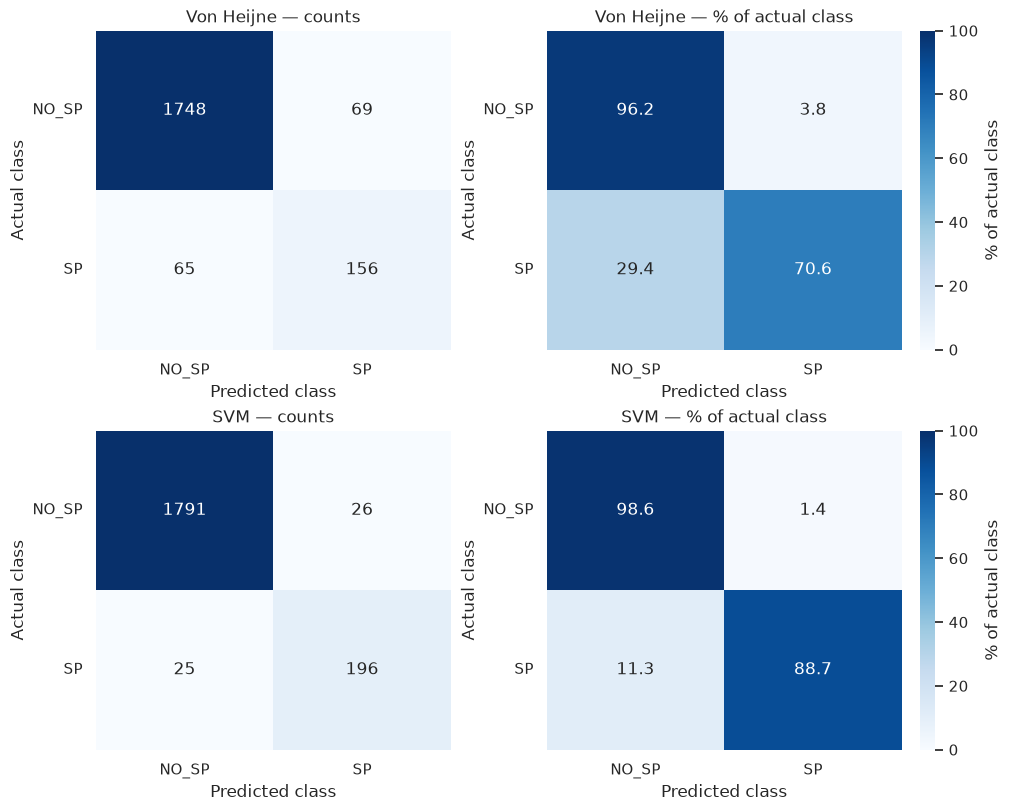

Plot saved in: ../results/figures/05/3_2_benchmark_metrics.pdf


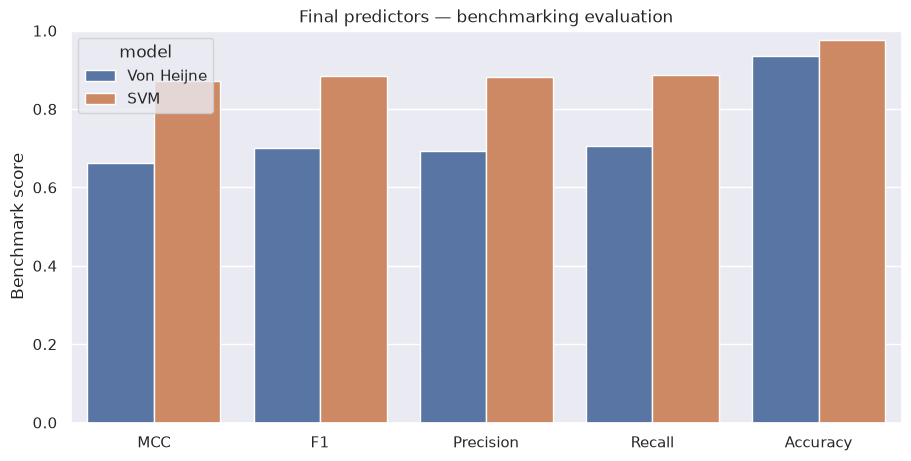

In [12]:
metric_columns = ["mcc", "f1", "precision", "recall", "accuracy"]
metric_labels = {"mcc": "MCC", "f1": "F1", "precision": "Precision",
                 "recall": "Recall", "accuracy": "Accuracy"}
metric_records = []
benchmark_confusion = {}
for model_name, predictions in model_predictions.items():
    actual = predictions["label"]
    predicted = predictions["prediction"]
    counts = pd.crosstab(actual, predicted).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    benchmark_confusion[model_name] = counts
    tn, fp, fn, tp = counts.to_numpy().ravel()
    metric_records.append({
        "model": model_name,
        "mcc": matthews_corrcoef(actual, predicted),
        "f1": f1_score(actual, predicted, zero_division=0),
        "precision": precision_score(actual, predicted, zero_division=0),
        "recall": recall_score(actual, predicted, zero_division=0),
        "accuracy": accuracy_score(actual, predicted),
        "tp": tp, "fn": fn, "fp": fp, "tn": tn,
    })
benchmark_metrics = pd.DataFrame(metric_records)
metrics_path = table_dir / "3_2_benchmark_metrics.tsv"
benchmark_metrics.to_csv(metrics_path, sep="\t", index=False)
print("Benchmark metrics saved in:", metrics_path)
display(benchmark_metrics.round(4))

# Counts and row percentages follow 04 section 6.5.
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
for row, (model_name, counts) in enumerate(benchmark_confusion.items()):
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    sns.heatmap(counts, ax=axes[row, 0], annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["NO_SP", "SP"], yticklabels=["NO_SP", "SP"])
    sns.heatmap(percentages, ax=axes[row, 1], annot=True, fmt=".1f", cmap="Blues",
                vmin=0, vmax=100, cbar_kws={"label": "% of actual class"},
                xticklabels=["NO_SP", "SP"], yticklabels=["NO_SP", "SP"])
    axes[row, 0].set_title(model_name + " — counts")
    axes[row, 1].set_title(model_name + " — % of actual class")
    for ax in axes[row]:
        ax.set(xlabel="Predicted class", ylabel="Actual class")
        ax.tick_params(axis="y", labelrotation=0)
figure_path = figure_dir / "3_2_benchmark_confusion.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", figure_path)
plt.show()

# Single benchmark estimates: no CV standard errors are attached.
metric_plot = benchmark_metrics.melt(
    id_vars="model", value_vars=metric_columns, var_name="metric", value_name="value"
)
metric_plot["metric"] = metric_plot["metric"].map(metric_labels)
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
sns.barplot(data=metric_plot, x="metric", y="value", hue="model",
            order=[metric_labels[m] for m in metric_columns], errorbar=None, ax=ax)
ax.set(xlabel="", ylabel="Benchmark score", ylim=(0, 1),
       title="Final predictors — benchmarking evaluation")
figure_path = figure_dir / "3_2_benchmark_metrics.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", figure_path)
plt.show()

## 4. False-positive analysis

### 4.1 Compare global and TM false-positive rates

**Inputs:** benchmarking predictions for both methods and negative metadata `has_tm_in_90`. This UniProt-derived flag already records whether a TM region starts within residues 1–90; the numerical TM-tendency feature is not a substitute for this annotation.

**To implement:** isolate each model's FP predictions and calculate:
- TM fraction among FP: `FP_TM / FP` (slide 5).
- Overall false-positive rate: `FP / (FP + TN)`.
- TM-restricted false-positive rate: `FP_TM / (FP_TM + TN_TM)`.

**Produce:** `4_1_fp_tm_analysis.tsv` with counts, denominators and fractions/rates for both models, plus a comparative rate plot. If a denominator is zero, report the rate as undefined.

The professor mentioned comparing the overall and TM-restricted false-positive rates because the fraction among FP alone does not account for TM abundance. Interpret any enrichment as an association; annotations alone do not prove the cause of an individual error.

## 5. False-negative analysis

### 5.1 Compare von Heijne TP and FN cleavage-site logos

**Inputs:** von Heijne benchmark TP/FN accessions, sequences and annotated cleavage positions. The existing training logo from 02c provides the expected motif reference.

**To implement:** extract the annotated 15-residue contexts for TP and FN and reuse 02c section 4's local WebLogo/Ghostscript procedure. Keep the same alphabet, colors, position labels and shared axis for the new comparison; report the number of contexts in each group.

**Produce:** group-specific context FASTA files under `../results/tables/05/` and TP/FN logo PDFs under `../results/figures/05/`.

Slide 6 requests an FN logo compared with the expected logo; the professor mentioned comparing TP and FN logos. Discuss motif differences descriptively and consider small FN sample sizes. Lower FN conservation is a hypothesis, not an observed result.

### 5.2 Compare SVM N-terminal composition

**Inputs:** positive training proteins, SVM benchmark TP/FN groups and the final n from 2.3.

**To implement:** calculate per-protein amino-acid composition within the first n residues and compare group summaries using the composition conventions in 02c and 04. Use the same n for all three groups. These are sequence compositions, not standardized SVM inputs.

**Produce:** `5_2_svm_composition.tsv` and a three-group composition PDF (slides 6–7). Explain any differences without changing n, features or the fitted model.

### 5.3 Compare SP lengths and selected features

**Inputs:** the same three positive groups, `cleavage_pos`, final n and the selected feature names from 2.3.

**To implement:** compare annotated SP-length distributions and the original-unit distributions of the selected SVM features. Reuse the feature extraction and plotting conventions from 04 and its supplementary exploration. Training positives are the reference group, not held-out predictions. Composition descriptors already shown in 5.2 need not be plotted again.

**Produce:** group counts and descriptive summaries in `5_3_svm_fn_features.tsv`, with numbered distribution PDFs (slides 6–7). The professor mentioned focusing on features selected in the final refit and gave a hydrophobicity boxplot as an example.

Describe overlap and differences without adding significance tests or redesigning the predictor after inspecting benchmarking errors.

## 6. Taxonomic errors and interpretation

### 6.1 Compare error profiles across taxa and species

**Inputs:** both methods' benchmark predictions and the existing `kingdom` and `organism` metadata.

**To implement:** count FP and FN by taxonomic group and species. Include the corresponding negative and positive totals, reporting `FP / N_negative` and `FN / N_positive` where defined. Use the taxonomy presentation conventions in 02c and keep small-group counts visible.

**Produce:** `6_1_taxonomic_errors.tsv` and concise comparative figures/tables (slide 4). Describe whether observed errors concentrate in particular groups while accounting for their representation; raw counts alone do not establish a higher error rate.

### 6.2 Interpretation and limitations

**To complete after execution:** compare the two models using the benchmarking metrics from 3.2, then interpret their TM-associated false positives, FN patterns and taxonomic error profiles (slides 4–8). Refer to the exported tables and figures and distinguish observations from possible explanations.

Keep 03–04 CV estimates as evaluations of the earlier procedures, final-search scores as parameter-selection records, and benchmarking metrics as the independent final comparison. Do not present search scores as an improved performance estimate or use benchmark errors to select a different model. The professor mentioned discussing these limitations in the report; later model improvements are outside this section.

**Expected output:** a short evidence-based account of the models' strengths and limitations. Error-analysis results and final conclusions remain pending.